In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Load the cleaned dataset
df = pd.read_csv(
    "../Dataset/Wednesday_Cleaned.csv.gz",
    compression="gzip",
    parse_dates=["Timestamp"]
)

# Display loading confirmation
print("Cleaned Dataset Loaded Successfully!")

# Display dataset dimensions
print("\nDataset Shape:", df.shape)

# Display first five records
print("\nFirst Five Records:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()


Cleaned Dataset Loaded Successfully!

Dataset Shape: (692686, 85)

First Five Records:


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.14-209.48.71.168-49459-80-6,192.168.10.14,49459,209.48.71.168,80,6,2017-07-05 08:42:00,38308.0,1,1,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
1,192.168.10.3-192.168.10.17-389-49453-6,192.168.10.17,49453,192.168.10.3,389,6,2017-07-05 08:42:00,479.0,11,5,...,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
2,192.168.10.3-192.168.10.17-88-46124-6,192.168.10.17,46124,192.168.10.3,88,6,2017-07-05 08:42:00,1095.0,10,6,...,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
3,192.168.10.3-192.168.10.17-389-49454-6,192.168.10.17,49454,192.168.10.3,389,6,2017-07-05 08:42:00,15206.0,17,12,...,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN
4,192.168.10.3-192.168.10.17-88-46126-6,192.168.10.17,46126,192.168.10.3,88,6,2017-07-05 08:42:00,1092.0,9,6,...,32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 692686 entries, 0 to 692685
Data columns (total 85 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   Flow ID                      692686 non-null  str           
 1   Source IP                    692686 non-null  str           
 2   Source Port                  692686 non-null  int64         
 3   Destination IP               692686 non-null  str           
 4   Destination Port             692686 non-null  int64         
 5   Protocol                     692686 non-null  int64         
 6   Timestamp                    692686 non-null  datetime64[us]
 7   Flow Duration                692665 non-null  float64       
 8   Total Fwd Packets            692686 non-null  int64         
 9   Total Backward Packets       692686 non-null  int64         
 10  Total Length of Fwd Packets  692686 non-null  int64         
 11  Total Length of

In [3]:
# Count records for each traffic label
label_counts = df["Label"].value_counts()

print("Traffic Label Counts:")
display(label_counts.to_frame(name="Record Count"))

# Calculate percentage distribution
label_percentages = (
    df["Label"].value_counts(normalize=True) * 100
)

print("\nTraffic Label Percentages:")
display(
    label_percentages.to_frame(name="Percentage (%)").round(4)
)

# Combine counts and percentages
label_distribution = pd.DataFrame({
    "Record Count": label_counts,
    "Percentage (%)": label_percentages
})

print("\nComplete Traffic Distribution:")
display(label_distribution.round(4))


Traffic Label Counts:


,Record Count
Label,
BENIGN,440015
DoS Hulk,231072
DoS GoldenEye,10293
DoS slowloris,5796
DoS Slowhttptest,5499
Heartbleed,11



Traffic Label Percentages:


,Percentage (%)
Label,
BENIGN,63.5230
DoS Hulk,33.3588
DoS GoldenEye,1.4860
DoS slowloris,0.8367
DoS Slowhttptest,0.7939
Heartbleed,0.0016



Complete Traffic Distribution:


,Record Count,Percentage (%)
Label,,
BENIGN,440015,63.5230
DoS Hulk,231072,33.3588
DoS GoldenEye,10293,1.4860
DoS slowloris,5796,0.8367
DoS Slowhttptest,5499,0.7939
Heartbleed,11,0.0016


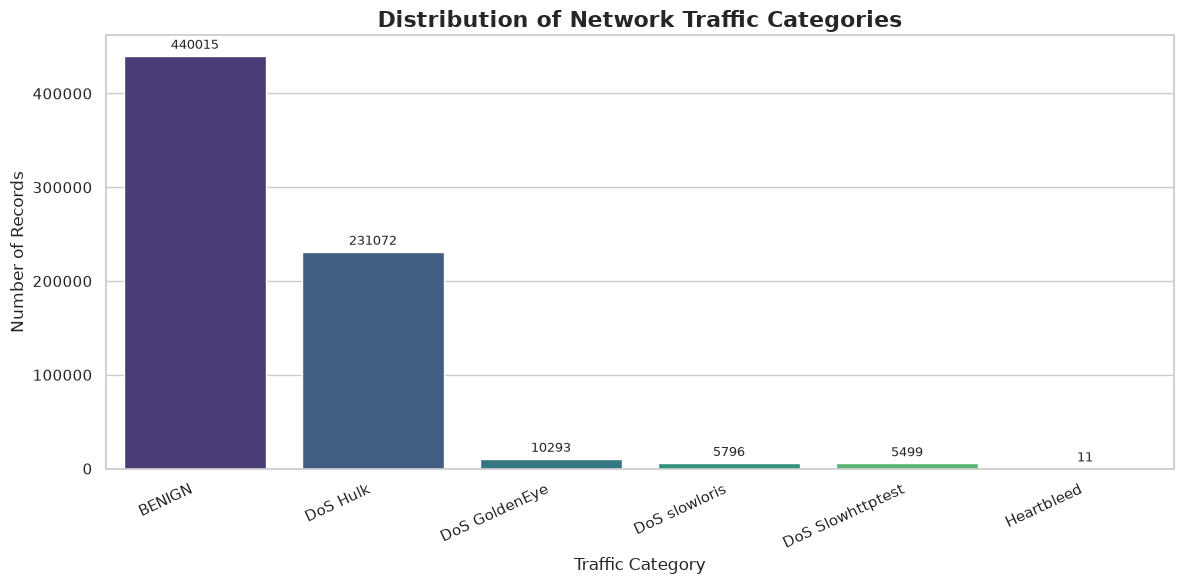

In [4]:
# Calculate traffic label counts
label_counts = df["Label"].value_counts()

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = sns.barplot(
    x=label_counts.index,
    y=label_counts.values,
    hue=label_counts.index,
    palette="viridis",
    legend=False
)

# Add chart title and axis labels
plt.title("Distribution of Network Traffic Categories",
          fontsize=16, fontweight="bold")

plt.xlabel("Traffic Category", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

# Rotate category labels
plt.xticks(rotation=25, ha="right")

# Add record counts above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3, fontsize=9)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()


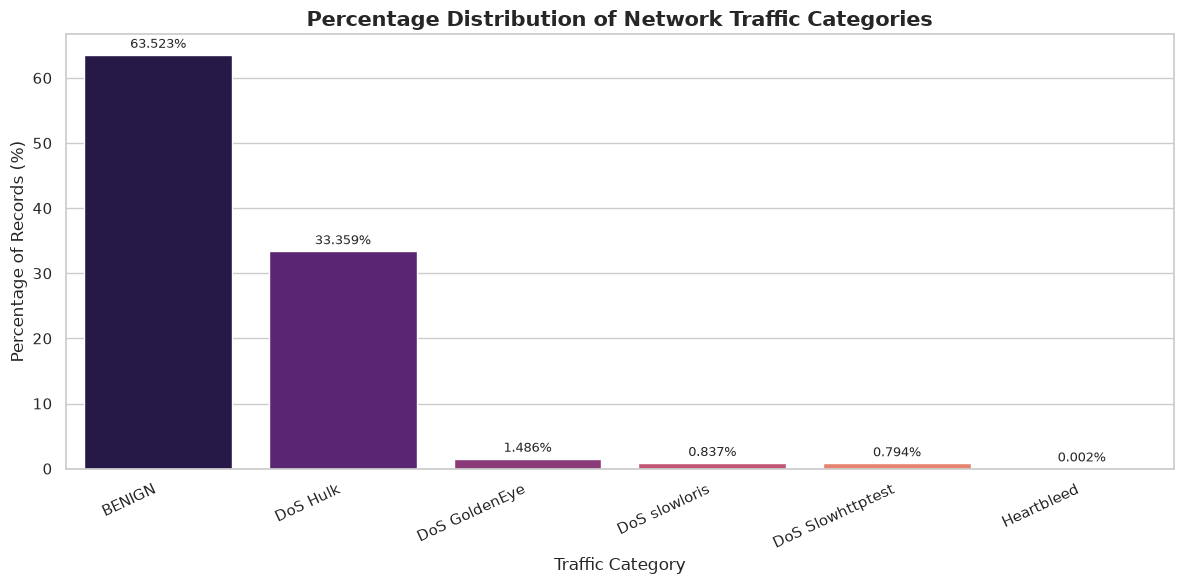

In [5]:
# Calculate percentage distribution
label_percentages = df["Label"].value_counts(normalize=True) * 100

# Create figure
plt.figure(figsize=(12, 6))

# Create bar chart
ax = sns.barplot(
    x=label_percentages.index,
    y=label_percentages.values,
    hue=label_percentages.index,
    palette="magma",
    legend=False
)

# Add chart title
plt.title(
    "Percentage Distribution of Network Traffic Categories",
    fontsize=15,
    fontweight="bold"
)

# Add axis labels
plt.xlabel("Traffic Category", fontsize=12)
plt.ylabel("Percentage of Records (%)", fontsize=12)

# Rotate category labels
plt.xticks(rotation=25, ha="right")

# Display percentage values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f%%",
        padding=3,
        fontsize=9
    )

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()


In [6]:
# Create a new binary traffic category
df["Traffic Type"] = np.where(
    df["Label"] == "BENIGN",
    "BENIGN",
    "ATTACK"
)

# Count records in each traffic type
traffic_counts = df["Traffic Type"].value_counts()

print("Benign vs Attack Traffic Counts:")
display(traffic_counts.to_frame(name="Record Count"))

# Calculate percentage distribution
traffic_percentages = (
    df["Traffic Type"].value_counts(normalize=True) * 100
)

print("\nBenign vs Attack Traffic Percentages:")
display(
    traffic_percentages.to_frame(name="Percentage (%)").round(4)
)


Benign vs Attack Traffic Counts:


,Record Count
Traffic Type,
BENIGN,440015
ATTACK,252671



Benign vs Attack Traffic Percentages:


,Percentage (%)
Traffic Type,
BENIGN,63.523
ATTACK,36.477


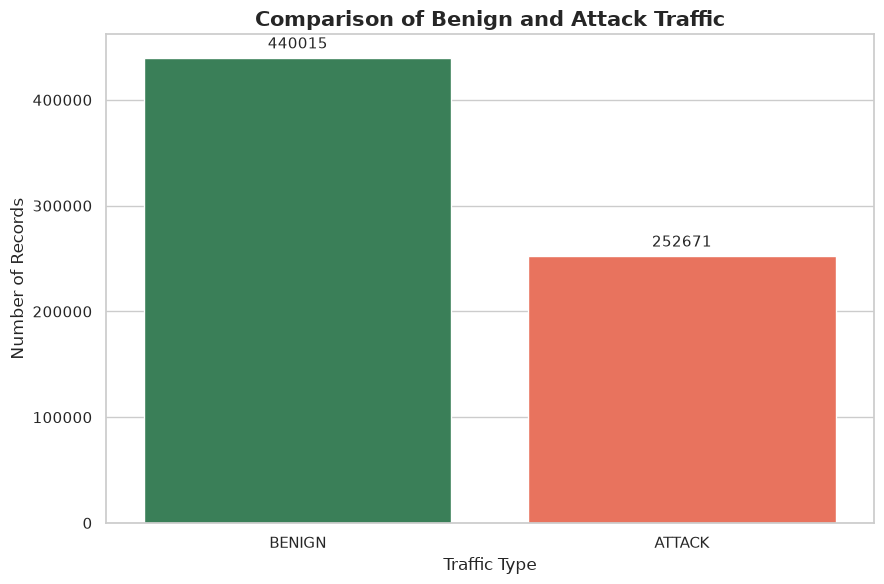

In [7]:
# Calculate traffic counts
traffic_counts = df["Traffic Type"].value_counts()

# Create figure
plt.figure(figsize=(9, 6))

# Create bar chart
ax = sns.barplot(
    x=traffic_counts.index,
    y=traffic_counts.values,
    hue=traffic_counts.index,
    palette=["seagreen", "tomato"],
    legend=False
)

# Add chart title
plt.title(
    "Comparison of Benign and Attack Traffic",
    fontsize=15,
    fontweight="bold"
)

# Add axis labels
plt.xlabel("Traffic Type", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

# Display record counts above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4,
        fontsize=11
    )

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()


In [8]:
# Extract only attack records
attack_df = df[df["Label"] != "BENIGN"].copy()

# Count records for each attack category
attack_counts = attack_df["Label"].value_counts()

print("Total Attack Records:", len(attack_df))

print("\nAttack Category Counts:")
display(
    attack_counts.to_frame(name="Record Count")
)

# Calculate percentage distribution among attack records
attack_percentages = (
    attack_counts / len(attack_df) * 100
)

print("\nAttack Category Percentages:")
display(
    attack_percentages.to_frame(name="Percentage (%)").round(4)
)


Total Attack Records: 252671

Attack Category Counts:


,Record Count
Label,
DoS Hulk,231072
DoS GoldenEye,10293
DoS slowloris,5796
DoS Slowhttptest,5499
Heartbleed,11



Attack Category Percentages:


,Percentage (%)
Label,
DoS Hulk,91.4517
DoS GoldenEye,4.0737
DoS slowloris,2.2939
DoS Slowhttptest,2.1763
Heartbleed,0.0044


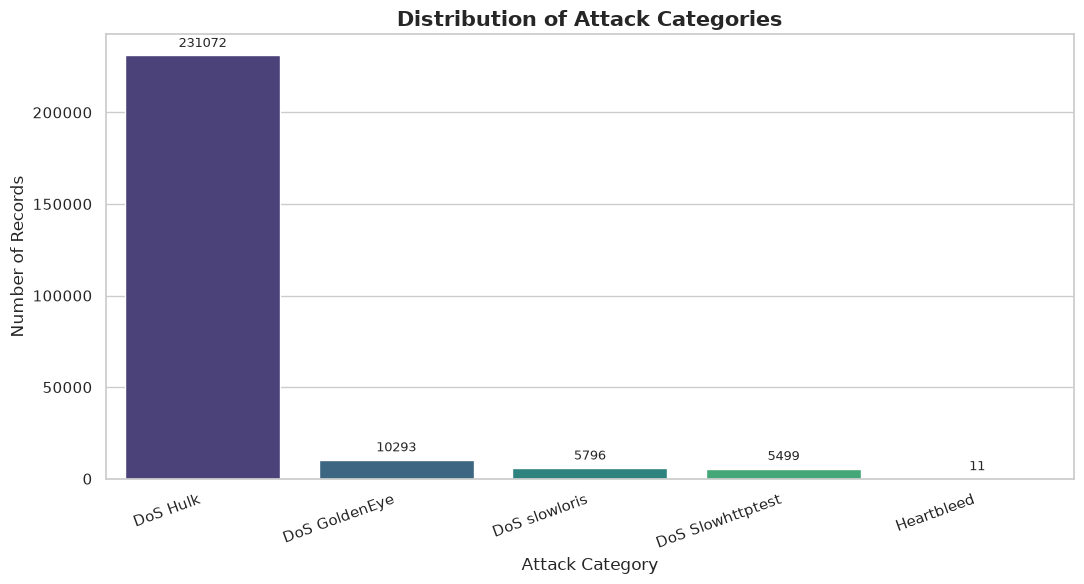

In [9]:
# Calculate attack category counts
attack_counts = (
    df[df["Label"] != "BENIGN"]["Label"]
    .value_counts()
)

# Create the figure
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x=attack_counts.index,
    y=attack_counts.values,
    hue=attack_counts.index,
    palette="viridis",
    legend=False
)

# Add chart title and axis labels
plt.title(
    "Distribution of Attack Categories",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Attack Category", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)

# Add record counts above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4,
        fontsize=9
    )

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [10]:
# Select numerical columns only
numeric_df = df.select_dtypes(include=np.number)

# Generate statistical summary
statistical_summary = numeric_df.describe().T

# Display the summary
display(statistical_summary.round(3))

# Display the total number of numerical features
print("Total Numerical Features:", numeric_df.shape[1])


,count,mean,std,min,25%,50%,75%,max
Source Port,692686.0,4.258465e+04,1.953511e+04,0.0,36236.0,49823.0,56892.0,65535.0
Destination Port,692686.0,5.685714e+03,1.572574e+04,0.0,53.0,80.0,443.0,65487.0
Protocol,692686.0,9.220000e+00,5.010000e+00,0.0,6.0,6.0,17.0,17.0
Flow Duration,692665.0,2.800322e+07,4.276747e+07,0.0,201.0,61443.0,83026089.0,119999998.0
Total Fwd Packets,692686.0,9.556000e+00,7.472070e+02,1.0,2.0,2.0,7.0,203943.0
...,...,...,...,...,...,...,...,...
Active Min,692686.0,6.315341e+04,6.051096e+05,0.0,0.0,0.0,988.0,100000000.0
Idle Mean,692686.0,2.211176e+07,3.812446e+07,0.0,0.0,0.0,15900000.0,120000000.0
Idle Std,692686.0,4.743860e+05,4.488566e+06,0.0,0.0,0.0,0.0,76900000.0
Idle Max,692686.0,2.252229e+07,3.848323e+07,0.0,0.0,0.0,16500000.0,120000000.0


Total Numerical Features: 80


In [11]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate skewness for each numerical feature
skewness_values = numeric_df.skew()

# Create a DataFrame for better presentation
skewness_summary = pd.DataFrame({
    "Skewness": skewness_values
})

# Sort features by absolute skewness
skewness_summary["Absolute Skewness"] = (
    skewness_summary["Skewness"].abs()
)

skewness_summary = skewness_summary.sort_values(
    by="Absolute Skewness",
    ascending=False
)

# Display the 15 most skewed features
print("Top 15 Highly Skewed Numerical Features:")
display(skewness_summary.head(15).round(4))


Top 15 Highly Skewed Numerical Features:


,Skewness,Absolute Skewness
Total Backward Packets,245.6029,245.6029
Subflow Bwd Packets,245.6029,245.6029
Bwd Header Length,245.3931,245.3931
Fwd Header Length.1,244.7315,244.7315
Fwd Header Length,244.7315,244.7315
Total Fwd Packets,244.2298,244.2298
Subflow Fwd Packets,244.2298,244.2298
act_data_pkt_fwd,244.1861,244.1861
Subflow Bwd Bytes,243.4355,243.4355
Total Length of Bwd Packets,243.4241,243.4241


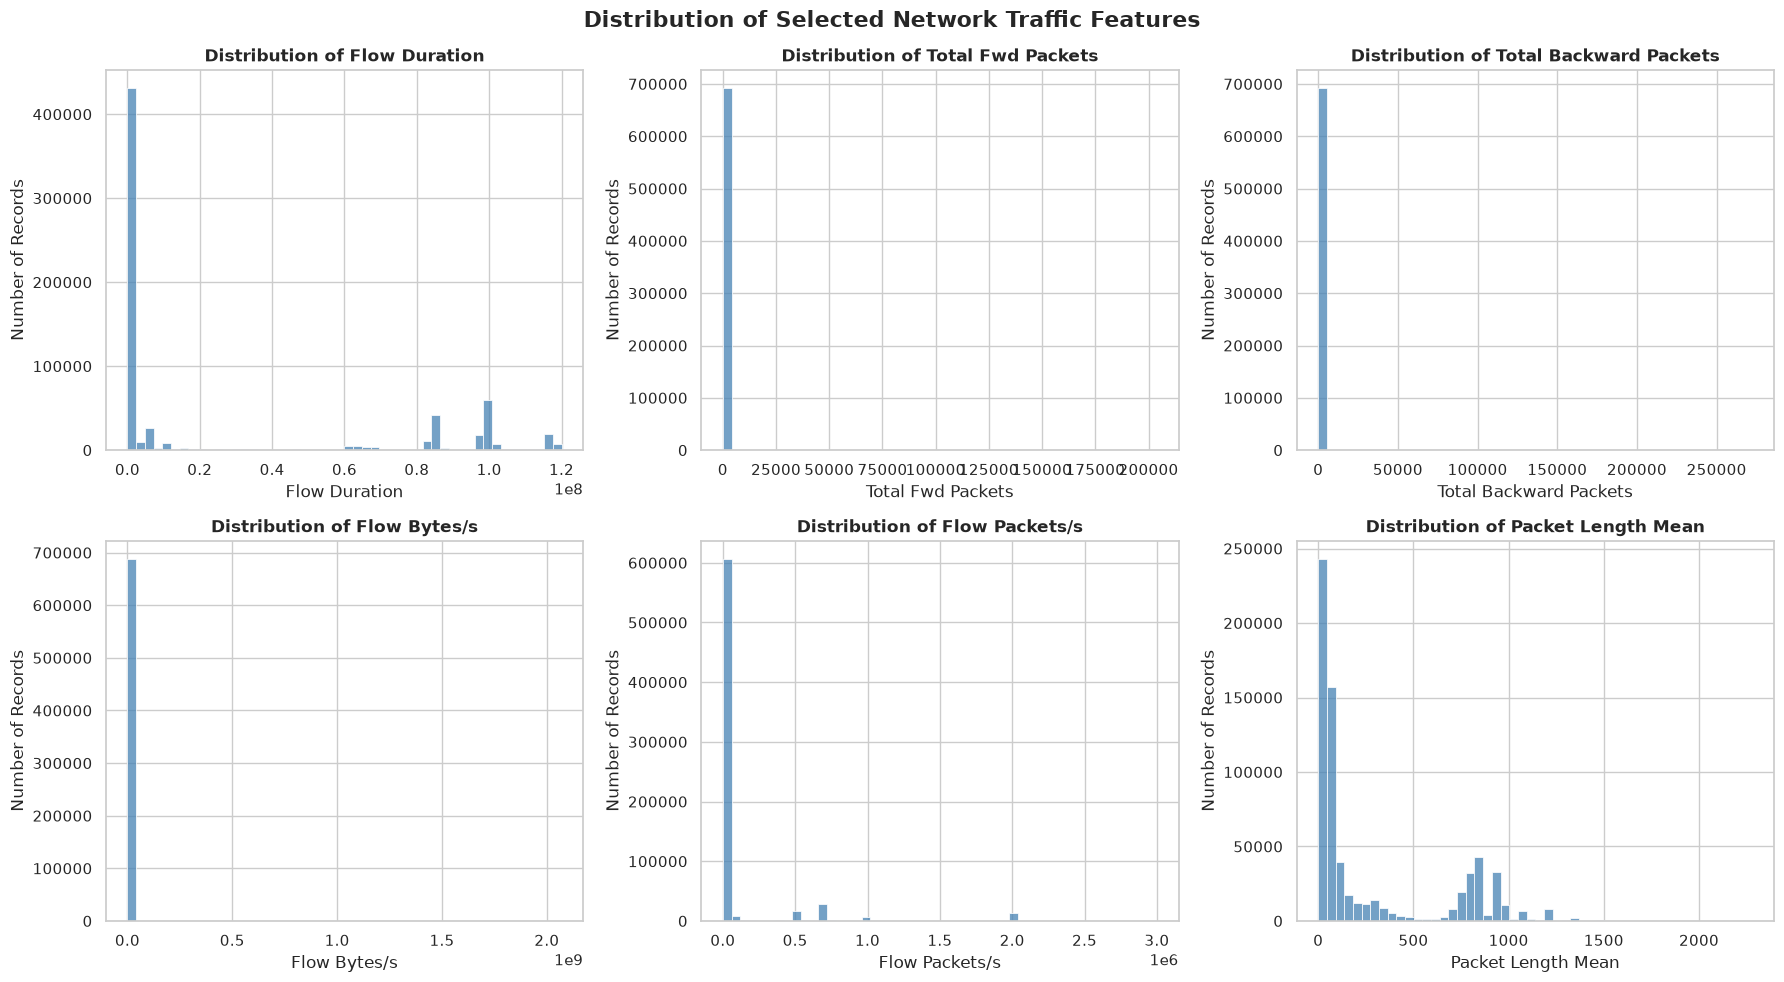

In [12]:
# Select important numerical features
selected_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean"
]

# Create histogram plots
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10)
)

axes = axes.flatten()

for i, feature in enumerate(selected_features):

    sns.histplot(
        data=df,
        x=feature,
        bins=50,
        kde=False,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(
        f"Distribution of {feature}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Number of Records")

plt.suptitle(
    "Distribution of Selected Network Traffic Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [13]:
# Create binary traffic category
df["Traffic Type"] = np.where(
    df["Label"] == "BENIGN",
    "BENIGN",
    "ATTACK"
)

# Display traffic category counts
print("Traffic Type Distribution:")
display(df["Traffic Type"].value_counts())


Traffic Type Distribution:


Traffic Type
BENIGN    440015
ATTACK    252671
Name: count, dtype: int64

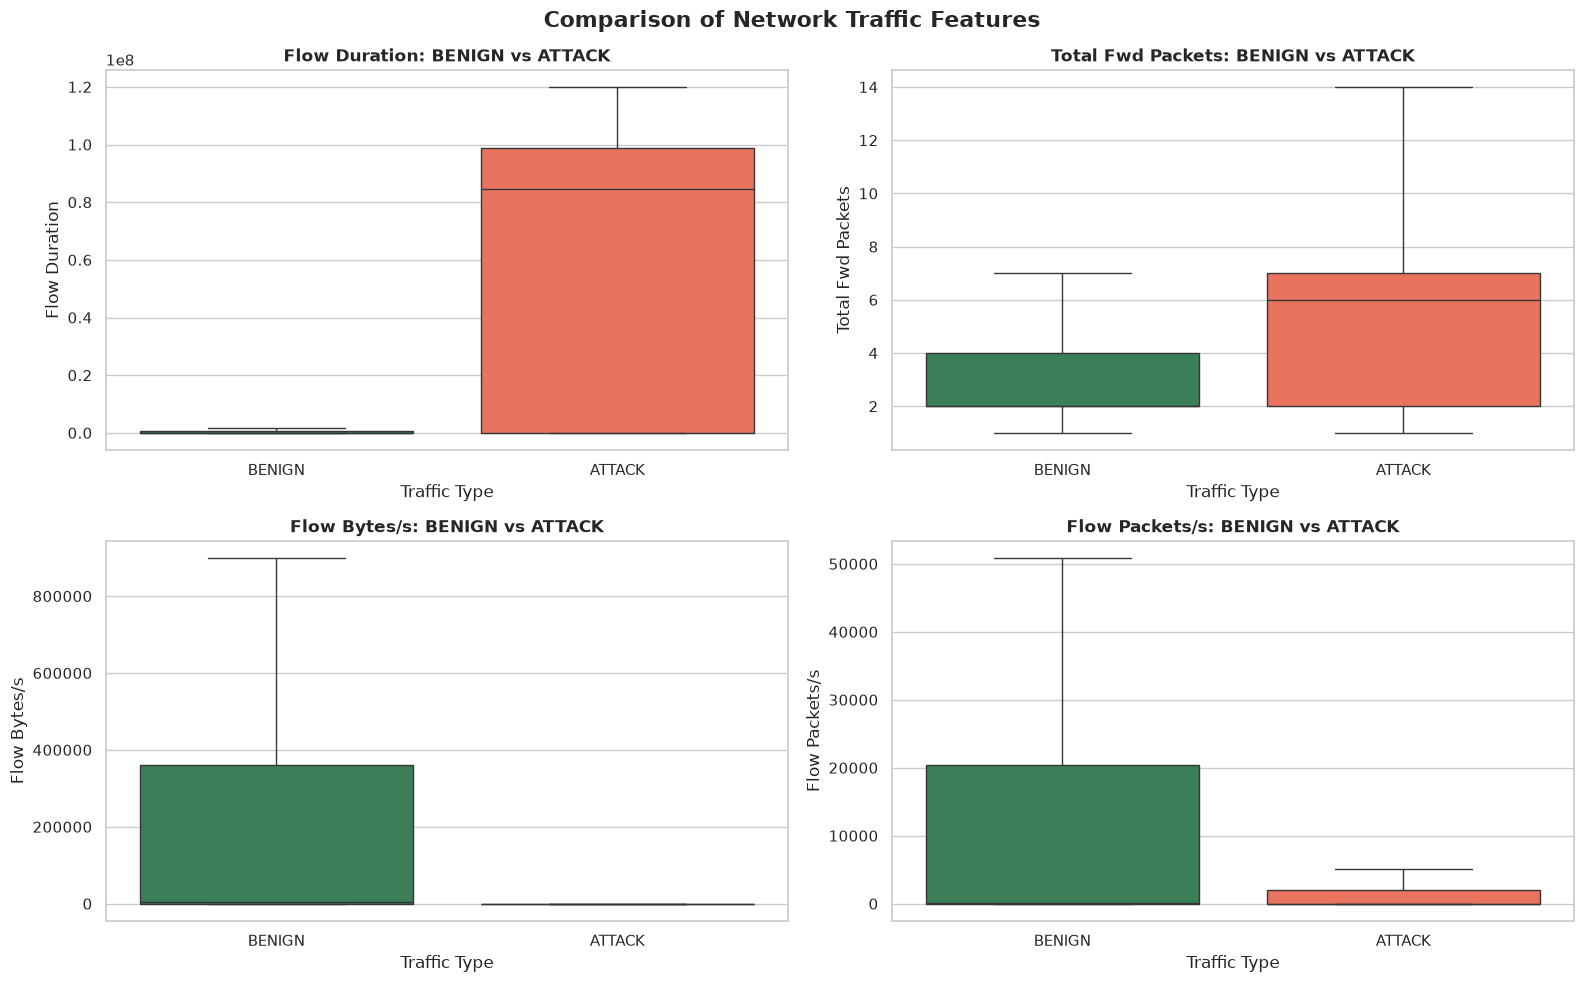

In [14]:

# Select features for comparison
comparison_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s"
]

# Create box plots
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(16, 10)
)

axes = axes.flatten()

for i, feature in enumerate(comparison_features):

    sns.boxplot(
        data=df,
        x="Traffic Type",
        y=feature,
        hue="Traffic Type",
        ax=axes[i],
        palette=["seagreen", "tomato"],
        legend=False,
        showfliers=False
    )

    axes[i].set_title(
        f"{feature}: BENIGN vs ATTACK",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("Traffic Type")
    axes[i].set_ylabel(feature)

plt.suptitle(
    "Comparison of Network Traffic Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


In [15]:
# Select important numerical features
comparison_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean"
]

# Calculate mean values
mean_comparison = df.groupby("Traffic Type")[
    comparison_features
].mean().T

# Calculate median values
median_comparison = df.groupby("Traffic Type")[
    comparison_features
].median().T

# Display mean comparison
print("Mean Comparison: BENIGN vs ATTACK")
display(mean_comparison.round(3))

# Display median comparison
print("\nMedian Comparison: BENIGN vs ATTACK")
display(median_comparison.round(3))


Mean Comparison: BENIGN vs ATTACK


Traffic Type,ATTACK,BENIGN
Flow Duration,5.570289e+07,1.209640e+07
Total Fwd Packets,5.452000e+00,1.191400e+01
Total Backward Packets,4.139000e+00,1.370300e+01
Flow Bytes/s,5.007115e+05,2.433328e+06
Flow Packets/s,1.674331e+05,6.084553e+04
Packet Length Mean,5.657100e+02,1.131860e+02



Median Comparison: BENIGN vs ATTACK


Traffic Type,ATTACK,BENIGN
Flow Duration,8.456418e+07,31048.000
Total Fwd Packets,6.000000e+00,2.000
Total Backward Packets,6.000000e+00,2.000
Flow Bytes/s,1.211180e+02,5390.605
Flow Packets/s,1.640000e-01,101.033
Packet Length Mean,7.950670e+02,61.000


In [16]:
# Select important numerical features
correlation_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Packet Length Std",
    "Packet Length Variance"
]

# Calculate Pearson correlation matrix
correlation_matrix = df[correlation_features].corr(
    method="pearson"
)

# Display correlation matrix
display(correlation_matrix.round(3))


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Packet Length Mean,Packet Length Std,Packet Length Variance
Flow Duration,1.000,0.015,0.014,0.082,0.012,-0.038,-0.202,0.681,0.702,0.580
Total Fwd Packets,0.015,1.000,0.999,0.726,0.996,0.000,-0.003,0.018,0.008,0.004
Total Backward Packets,0.014,0.999,1.000,0.726,0.993,0.000,-0.003,0.019,0.008,0.004
Total Length of Fwd Packets,0.082,0.726,0.726,1.000,0.720,0.005,-0.026,0.095,0.064,0.040
Total Length of Bwd Packets,0.012,0.996,0.993,0.720,1.000,0.000,-0.002,0.018,0.008,0.005
Flow Bytes/s,-0.038,0.000,0.000,0.005,0.000,1.000,0.178,0.050,-0.001,-0.012
Flow Packets/s,-0.202,-0.003,-0.003,-0.026,-0.002,0.178,1.000,-0.215,-0.200,-0.155
Packet Length Mean,0.681,0.018,0.019,0.095,0.018,0.050,-0.215,1.000,0.954,0.844
Packet Length Std,0.702,0.008,0.008,0.064,0.008,-0.001,-0.200,0.954,1.000,0.947
Packet Length Variance,0.580,0.004,0.004,0.040,0.005,-0.012,-0.155,0.844,0.947,1.000


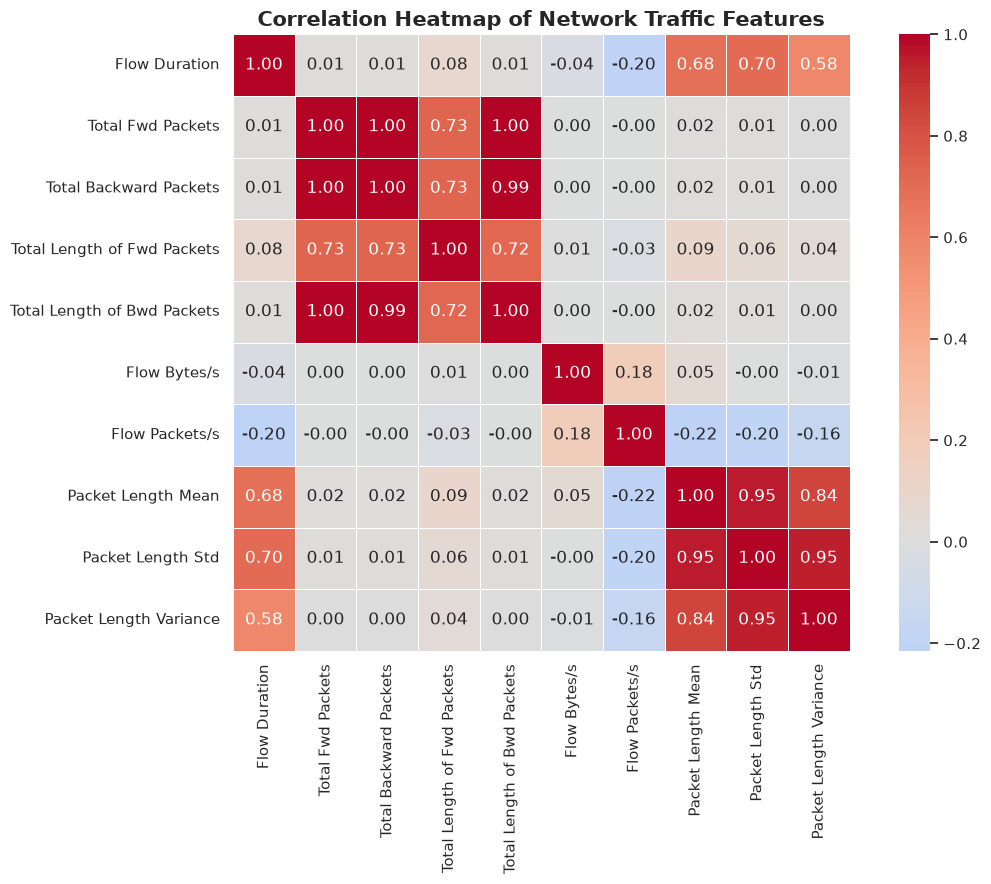

In [17]:

# Create correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Heatmap of Network Traffic Features",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [18]:
# Verify timestamp data type
print("Timestamp Data Type:", df["Timestamp"].dtype)

# Check timestamp range
print("Starting Time:", df["Timestamp"].min())
print("Ending Time:", df["Timestamp"].max())

# Check missing timestamps
print("Missing Timestamps:", df["Timestamp"].isna().sum())


Timestamp Data Type: datetime64[us]
Starting Time: 2017-07-05 01:00:00
Ending Time: 2017-07-05 12:59:00
Missing Timestamps: 0


In [19]:

# Group network traffic records by minute
traffic_per_minute = (
    df.set_index("Timestamp")
      .resample("1min")
      .size()
)

# Convert result into a DataFrame
traffic_per_minute = traffic_per_minute.reset_index(
    name="Record Count"
)

# Display first few records
display(traffic_per_minute.head(10))

# Display maximum traffic in a minute
print(
    "Maximum Records in One Minute:",
    traffic_per_minute["Record Count"].max()
)


,Timestamp,Record Count
0,2017-07-05 01:00:00,449
1,2017-07-05 01:01:00,149
2,2017-07-05 01:02:00,99
3,2017-07-05 01:03:00,277
4,2017-07-05 01:04:00,143
5,2017-07-05 01:05:00,1564
6,2017-07-05 01:06:00,146
7,2017-07-05 01:07:00,237
8,2017-07-05 01:08:00,821
9,2017-07-05 01:09:00,333


Maximum Records in One Minute: 18353


In [20]:

# Import Plotly Express
import plotly.express as px

# Create interactive line chart
fig = px.line(
    traffic_per_minute,
    x="Timestamp",
    y="Record Count",
    title="Network Traffic Volume Over Time",
    labels={
        "Timestamp": "Time",
        "Record Count": "Number of Network Flows"
    }
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white",
    hovermode="x unified"
)

fig.show()


In [ ]:

# Group traffic by minute and traffic type
traffic_time_analysis = (
    df.set_index("Timestamp")
      .groupby("Traffic Type")
      .resample("1min")
      .size()
      .unstack(level=0)
      .fillna(0)
)

# Display the first 10 records
display(traffic_time_analysis.head(10))

# Display total records for each traffic type
print("\nTotal Traffic Records:")
display(traffic_time_analysis.sum())


Traffic Type,ATTACK,BENIGN
Timestamp,,
2017-07-05 01:00:00,0.0,449.0
2017-07-05 01:01:00,0.0,149.0
2017-07-05 01:02:00,0.0,99.0
2017-07-05 01:03:00,0.0,277.0
2017-07-05 01:04:00,0.0,143.0
2017-07-05 01:05:00,0.0,1564.0
2017-07-05 01:06:00,0.0,146.0
2017-07-05 01:07:00,0.0,237.0
2017-07-05 01:08:00,0.0,821.0



Total Traffic Records:


Traffic Type
ATTACK    252671.0
BENIGN    440015.0
dtype: float64

In [26]:

# ==========================================
# INTERACTIVE TIME-BASED TRAFFIC CHART
# ==========================================

fig = px.line(
    traffic_time_analysis.reset_index(),
    x="Timestamp",
    y=["BENIGN", "ATTACK"],
    title="BENIGN vs ATTACK Traffic Over Time",
    labels={
        "Timestamp": "Time",
        "value": "Number of Network Flows",
        "variable": "Traffic Type"
    }
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white",
    hovermode="x unified",
    legend_title="Traffic Category"
)

fig.show()


In [27]:

# ==========================================
# PHASE 4: EXPLORATORY DATA ANALYSIS
# STEP 17: ATTACK CATEGORY TRENDS
# ==========================================

# Extract attack records only
attack_df = df[df["Label"] != "BENIGN"].copy()

# Group attack records by minute and category
attack_time_analysis = (
    attack_df.set_index("Timestamp")
             .groupby("Label")
             .resample("1min")
             .size()
             .unstack(level=0)
             .fillna(0)
)

# Display the first 10 records
display(attack_time_analysis.head(10))

# Display total records for each attack category
print("\nTotal Records by Attack Category:")
display(attack_time_analysis.sum())


Label,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,Heartbleed
Timestamp,,,,,
2017-07-05 02:24:00,0.0,0.0,0.0,4.0,0.0
2017-07-05 02:25:00,0.0,0.0,0.0,1.0,0.0
2017-07-05 02:26:00,0.0,0.0,0.0,0.0,0.0
2017-07-05 02:27:00,0.0,0.0,0.0,0.0,0.0
2017-07-05 02:28:00,0.0,0.0,0.0,0.0,0.0
2017-07-05 02:29:00,0.0,0.0,0.0,0.0,0.0
2017-07-05 02:30:00,0.0,0.0,0.0,0.0,0.0
2017-07-05 02:31:00,0.0,0.0,0.0,0.0,0.0
2017-07-05 02:32:00,0.0,0.0,0.0,0.0,0.0



Total Records by Attack Category:


Label
DoS GoldenEye        10293.0
DoS Hulk            231072.0
DoS Slowhttptest      5499.0
DoS slowloris         5796.0
Heartbleed              11.0
dtype: float64

In [28]:

# ==========================================
# INTERACTIVE ATTACK CATEGORY TIME CHART
# ==========================================

fig = px.line(
    attack_time_analysis.reset_index(),
    x="Timestamp",
    y=attack_time_analysis.columns,
    title="Attack Category Trends Over Time",
    labels={
        "Timestamp": "Time",
        "value": "Number of Attack Flows",
        "variable": "Attack Category"
    }
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white",
    hovermode="x unified",
    legend_title="Attack Category"
)

fig.show()


In [29]:

# ==========================================
# PHASE 4: EXPLORATORY DATA ANALYSIS
# STEP 18: TRAFFIC DISTRIBUTION BY TIME INTERVAL
# ==========================================

# Group records into 30-minute intervals
traffic_30min = (
    df.set_index("Timestamp")
      .groupby("Traffic Type")
      .resample("30min")
      .size()
      .unstack(level=0)
      .fillna(0)
)

# Calculate total traffic in each interval
traffic_30min["Total Traffic"] = (
    traffic_30min.sum(axis=1)
)

# Display results
print("Traffic Distribution by 30-Minute Interval:")
display(traffic_30min)

# Find the interval with the highest total traffic
highest_interval = traffic_30min["Total Traffic"].idxmax()

print("\nInterval with Highest Traffic:")
print(highest_interval)

print(
    "Total Records:",
    int(traffic_30min.loc[highest_interval, "Total Traffic"])
)


Traffic Distribution by 30-Minute Interval:


Traffic Type,ATTACK,BENIGN,Total Traffic
Timestamp,,,
2017-07-05 01:00:00,0.0,22746.0,22746.0
2017-07-05 01:30:00,0.0,26156.0,26156.0
2017-07-05 02:00:00,5.0,29426.0,29431.0
2017-07-05 02:30:00,0.0,34437.0,34437.0
2017-07-05 03:00:00,9.0,47467.0,47476.0
2017-07-05 03:30:00,2.0,18662.0,18664.0
2017-07-05 04:00:00,0.0,23862.0,23862.0
2017-07-05 04:30:00,0.0,21015.0,21015.0
2017-07-05 05:00:00,0.0,3535.0,3535.0



Interval with Highest Traffic:
2017-07-05 10:30:00
Total Records: 257810


In [30]:

# ==========================================
# INTERACTIVE 30-MINUTE TRAFFIC CHART
# ==========================================

traffic_30min_plot = (
    traffic_30min.reset_index()
    .melt(
        id_vars="Timestamp",
        value_vars=["BENIGN", "ATTACK"],
        var_name="Traffic Type",
        value_name="Record Count"
    )
)

fig = px.bar(
    traffic_30min_plot,
    x="Timestamp",
    y="Record Count",
    color="Traffic Type",
    barmode="group",
    title="BENIGN vs ATTACK Traffic by 30-Minute Interval",
    labels={
        "Timestamp": "Time Interval",
        "Record Count": "Number of Network Flows"
    },
    color_discrete_map={
        "BENIGN": "seagreen",
        "ATTACK": "tomato"
    }
)

fig.update_layout(
    title_x=0.5,
    template="plotly_white",
    xaxis_tickangle=-45,
    hovermode="x unified"
)

fig.show()


In [31]:

# ==========================================
# PHASE 4: EXPLORATORY DATA ANALYSIS
# STEP 19: DETAILED EDA FINDINGS
# ==========================================

# Total records
total_records = len(df)

# Benign and attack counts
traffic_counts = df["Traffic Type"].value_counts()

# Attack category counts
attack_counts = (
    df[df["Label"] != "BENIGN"]["Label"]
    .value_counts()
)

# Missing values
missing_values = df.isnull().sum()
total_missing = missing_values.sum()

# Timestamp information
start_time = df["Timestamp"].min()
end_time = df["Timestamp"].max()

# Create summary
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Network Records",
        "BENIGN Records",
        "ATTACK Records",
        "Number of Attack Categories",
        "Total Missing Values",
        "Capture Start Time",
        "Capture End Time"
    ],
    "Value": [
        total_records,
        traffic_counts.get("BENIGN", 0),
        traffic_counts.get("ATTACK", 0),
        len(attack_counts),
        total_missing,
        start_time,
        end_time
    ]
})

print("EDA SUMMARY:")
display(eda_summary)

print("\nATTACK CATEGORY SUMMARY:")
display(attack_counts.to_frame(name="Record Count"))

print("\nTOP 10 FEATURES WITH MISSING VALUES:")
display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="Missing Values")
)


EDA SUMMARY:


,Metric,Value
0,Total Network Records,692686
1,BENIGN Records,440015
2,ATTACK Records,252671
3,Number of Attack Categories,5
4,Total Missing Values,2650
5,Capture Start Time,2017-07-05 01:00:00
6,Capture End Time,2017-07-05 12:59:00



ATTACK CATEGORY SUMMARY:


,Record Count
Label,
DoS Hulk,231072
DoS GoldenEye,10293
DoS slowloris,5796
DoS Slowhttptest,5499
Heartbleed,11



TOP 10 FEATURES WITH MISSING VALUES:


,Missing Values
Flow Packets/s,1317
Flow Bytes/s,1312
Flow Duration,21


In [32]:

# ==========================================
# PHASE 4: EXPLORATORY DATA ANALYSIS
# STEP 20: FINAL EDA SUMMARY
# ==========================================

# Total records
total_records = len(df)

# Traffic distribution
traffic_counts = df["Traffic Type"].value_counts()

# Traffic percentages
traffic_percentages = (
    df["Traffic Type"].value_counts(normalize=True) * 100
)

# Attack category distribution
attack_counts = (
    df[df["Label"] != "BENIGN"]["Label"]
    .value_counts()
)

attack_percentages = (
    attack_counts / attack_counts.sum() * 100
)

# Create final summary
final_eda_summary = pd.DataFrame({
    "Category": [
        "Total Records",
        "Total Features",
        "BENIGN Records",
        "ATTACK Records",
        "BENIGN Percentage",
        "ATTACK Percentage",
        "Attack Categories",
        "Missing Values",
        "Duplicate Records"
    ],
    "Value": [
        total_records,
        df.shape[1],
        traffic_counts.get("BENIGN", 0),
        traffic_counts.get("ATTACK", 0),
        round(traffic_percentages.get("BENIGN", 0), 4),
        round(traffic_percentages.get("ATTACK", 0), 4),
        len(attack_counts),
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum())
    ]
})

print("========== FINAL EDA SUMMARY ==========")
display(final_eda_summary)

print("\n========== ATTACK CATEGORY DISTRIBUTION ==========")

attack_summary = pd.DataFrame({
    "Record Count": attack_counts,
    "Percentage Among Attacks (%)": attack_percentages
})

display(attack_summary.round(4))


========== FINAL EDA SUMMARY ==========


,Category,Value
0,Total Records,692686.000
1,Total Features,86.000
2,BENIGN Records,440015.000
3,ATTACK Records,252671.000
4,BENIGN Percentage,63.523
5,ATTACK Percentage,36.477
6,Attack Categories,5.000
7,Missing Values,2650.000
8,Duplicate Records,0.000



========== ATTACK CATEGORY DISTRIBUTION ==========


,Record Count,Percentage Among Attacks (%)
Label,,
DoS Hulk,231072,91.4517
DoS GoldenEye,10293,4.0737
DoS slowloris,5796,2.2939
DoS Slowhttptest,5499,2.1763
Heartbleed,11,0.0044
